# Evaluation of the Transformer Genre Classifier

This notebook evaluates the fine-tuned `distilroberta-base` model from `transformers.ipynb` on the shared validation split (`data/validation_ids.parquet`, 33,742 songs), so the results can be compared directly with the other models of the project.

1. the validation and test predictions are computed once and saved, so later runs (and the other notebooks) only load them,
2. the training curves,
3. the overall metrics, the metrics per genre, and the confusion matrix,
4. a prior correction of the predictions, relevant if the Kaggle metric is accuracy,
5. examples of confident mistakes.

## Setup

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("device:", device)

device: mps


In [2]:
# The project root, which holds data/ and models/
project_dir = Path("..")
data_dir = project_dir / "data"
tran_dir = data_dir / "data-transformers"
model_dir = project_dir / "models" / "transformers" / "distilroberta-genre"
best_dir = model_dir / "best"
pred_dir = model_dir / "predictions"

BATCH_SIZE = 16   # training batch size of transformers.ipynb, to place the logged steps on an epoch axis

## Loading the Data

The same split as in `transformers.ipynb`. The genre names and their order are taken from the saved model config, so the label ids are guaranteed to match the model's outputs.

In [3]:
config = json.loads((best_dir / "config.json").read_text())
genres = [config["id2label"][str(k)] for k in range(len(config["id2label"]))]
label2id = {genre: k for k, genre in enumerate(genres)}

columns = ["id", "title", "artist", "tag", "lyrics_classification"]
songs = pl.read_parquet(tran_dir / "transformers_train.parquet", columns=columns)
df_test = pl.read_parquet(tran_dir / "transformers_test.parquet", columns=["id", "lyrics_classification"])
val_ids = pl.read_parquet(data_dir / "validation_ids.parquet")["id"]

df_train = songs.filter(~pl.col("id").is_in(val_ids.implode()))
df_val = (songs.filter(pl.col("id").is_in(val_ids.implode()))
          .with_columns(label=pl.col("tag").replace_strict(label2id)))
print(f"train: {len(df_train):,}  validation: {len(df_val):,}  test: {len(df_test):,}")
genres

train: 101,225  validation: 33,742  test: 33,742


['country', 'misc', 'pop', 'rap', 'rb', 'rock']

## Predictions

The model outputs one logit per genre; they are turned into probabilities with a softmax and saved together with the song `id` to `predictions/validation.parquet` and `predictions/test.parquet`. Predicting all 67k songs takes a few minutes on a GPU, so it is done only if the files don't exist yet (set `PREDICT = True` to recompute them).

As in training, the songs are sorted by length so a batch is padded as little as possible, and the predictions are put back into the original order afterwards.

In [4]:
PREDICT = not (pred_dir / "validation.parquet").exists()
EVAL_BATCH_SIZE = 64
prob_columns = [f"p_{genre}" for genre in genres]


def predict_probs(texts, model, tokenizer):
    input_ids = tokenizer(texts, truncation=True, max_length=512)["input_ids"]
    order = np.argsort([len(ids) for ids in input_ids], kind="stable")
    probs = np.empty((len(texts), len(genres)), dtype=np.float32)
    model.eval()
    with torch.no_grad():
        for start in tqdm(range(0, len(order), EVAL_BATCH_SIZE), desc="predicting"):
            idx = order[start:start + EVAL_BATCH_SIZE]
            batch = tokenizer.pad({"input_ids": [input_ids[i] for i in idx]}, return_tensors="pt").to(device)
            probs[idx] = torch.softmax(model(**batch).logits.float(), dim=-1).cpu().numpy()
    return probs


if PREDICT:
    from tqdm.auto import tqdm
    from transformers import AutoModelForSequenceClassification, AutoTokenizer

    tokenizer = AutoTokenizer.from_pretrained(best_dir)
    model = AutoModelForSequenceClassification.from_pretrained(best_dir).to(device)
    pred_dir.mkdir(parents=True, exist_ok=True)
    for name, df in [("validation", df_val), ("test", df_test)]:
        probs = predict_probs(df["lyrics_classification"].to_list(), model, tokenizer)
        (df.select("id").hstack(pl.DataFrame(probs, schema=prob_columns))
           .write_parquet(pred_dir / f"{name}.parquet"))

val_pred = df_val.join(pl.read_parquet(pred_dir / "validation.parquet"), on="id", how="left", maintain_order="left")
val_probs = val_pred.select(prob_columns).to_numpy()
y_true = val_pred["label"].to_numpy()
y_pred = val_probs.argmax(axis=1)
val_pred.select("id", "tag", *prob_columns).head()

id,tag,p_country,p_misc,p_pop,p_rap,p_rb,p_rock
i64,str,f32,f32,f32,f32,f32,f32
1584150,"""pop""",0.974515,0.000394,0.018595,0.000408,0.000622,0.005466
4260038,"""rap""",0.002585,0.065776,0.068959,0.84013,0.018891,0.003659
3822845,"""pop""",0.000814,0.008122,0.214435,0.730529,0.040511,0.005589
2235574,"""pop""",0.048835,0.013814,0.661936,0.001285,0.010718,0.263412
3876276,"""pop""",0.01726,0.029529,0.626779,0.00853,0.065481,0.252422


## Training Curves

The training loss (averaged over 200 steps) and the validation loss after each epoch. Both are the class-weighted cross-entropy, so they are on the same scale. The right panel shows the validation accuracy and macro-F1 after each epoch; the model of epoch 3 has the highest macro-F1 and is the one evaluated here.

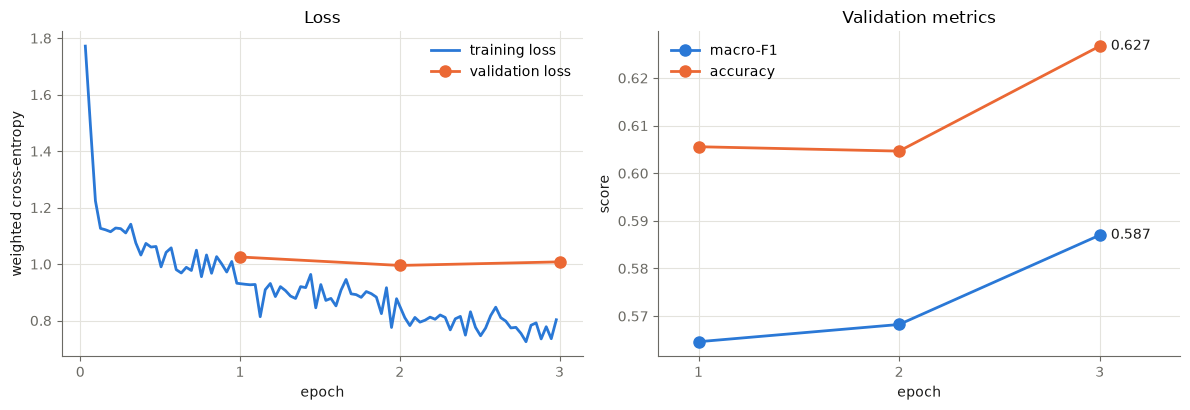

In [5]:
history = json.loads((model_dir / "history.json").read_text())
steps = pl.DataFrame(history["steps"])
epochs = pl.DataFrame(history["epochs"])
steps_per_epoch = math.ceil(len(df_train) / BATCH_SIZE)

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1a1a19", "#6b6a64", "#e4e3dd"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "font.size": 10})

fig, (ax_loss, ax_metric) = plt.subplots(1, 2, figsize=(12, 4.2))
ax_loss.plot(steps["step"] / steps_per_epoch, steps["train_loss"], color=BLUE, lw=2, label="training loss")
ax_loss.plot(epochs["epoch"], epochs["val_loss"], color=ORANGE, lw=2, marker="o", ms=8, label="validation loss")
ax_loss.set(xlabel="epoch", ylabel="weighted cross-entropy", title="Loss", xticks=[0, 1, 2, 3])

ax_metric.plot(epochs["epoch"], epochs["val_macro_f1"], color=BLUE, lw=2, marker="o", ms=8, label="macro-F1")
ax_metric.plot(epochs["epoch"], epochs["val_accuracy"], color=ORANGE, lw=2, marker="o", ms=8, label="accuracy")
for col, color in [("val_macro_f1", BLUE), ("val_accuracy", ORANGE)]:
    ax_metric.annotate(f"{epochs[col][-1]:.3f}", (3, epochs[col][-1]), xytext=(8, 0), textcoords="offset points",
                       va="center", color=INK)
ax_metric.set(xlabel="epoch", ylabel="score", title="Validation metrics", xticks=[1, 2, 3], xlim=(0.8, 3.4))
for ax in (ax_loss, ax_metric):
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Overall Metrics

- **Accuracy**: share of songs whose genre is predicted correctly. It is dominated by the large genres (pop and rap are 70% of the songs).
- **Macro-F1**: the F1-score (harmonic mean of precision and recall) computed for every genre and averaged with equal weight, so the small genres (country, misc, R&B) count as much as pop. This is the main metric for comparing the models.
- **Balanced accuracy**: the average recall over the genres.
- **Weighted F1**: the per-genre F1 averaged with the number of songs as weights.

In [6]:
def metrics(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "macro_precision": precision_score(y_true, y_pred, average="macro"),
            "macro_recall": recall_score(y_true, y_pred, average="macro"),
            "macro_f1": f1_score(y_true, y_pred, average="macro"),
            "weighted_f1": f1_score(y_true, y_pred, average="weighted")}


pl.DataFrame([metrics(y_true, y_pred)]).with_columns(pl.all().round(4))

accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
f64,f64,f64,f64,f64,f64
0.6268,0.6407,0.5783,0.6407,0.5872,0.6348


## Metrics per Genre

`support` is the number of validation songs of the genre. `predicted` is how many songs the model assigns to it: because of the class-weighted loss, the small genres are predicted more often than they occur (higher recall, lower precision).

In [7]:
report = classification_report(y_true, y_pred, target_names=genres, output_dict=True)
(pl.DataFrame([{"genre": genre, **report[genre]} for genre in genres])
    .with_columns(pl.col("support").cast(pl.Int64),
                  predicted=pl.Series(np.bincount(y_pred, minlength=len(genres))))
    .with_columns(pl.col("precision", "recall", "f1-score").round(3))
    .sort("support", descending=True))

genre,precision,recall,f1-score,support,predicted
str,f64,f64,f64,i64,i64
"""pop""",0.718,0.437,0.543,13936,8490
"""rap""",0.894,0.842,0.867,9646,9090
"""rock""",0.433,0.719,0.54,6333,10528
"""rb""",0.278,0.484,0.353,1551,2693
"""misc""",0.851,0.821,0.836,1410,1361
"""country""",0.296,0.54,0.383,866,1580


## Confusion Matrix

Rows are the true genres, columns the predicted ones. The left matrix shows the number of songs, the right one the share of each true genre (each row sums to 100%, the diagonal is the recall). Both are coloured by the row share, so the small genres are as visible as pop.

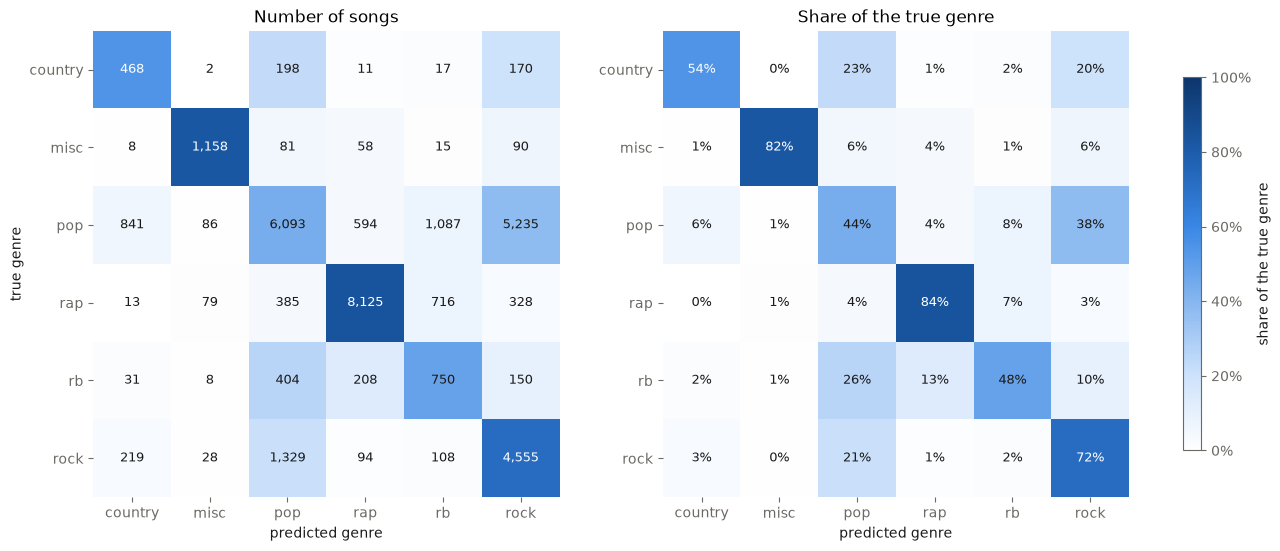

In [8]:
cm = confusion_matrix(y_true, y_pred)
cm_share = cm / cm.sum(axis=1, keepdims=True)
cmap = LinearSegmentedColormap.from_list("blue", ["#ffffff", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), layout="constrained")
for ax, values, fmt, title in [(axes[0], cm, "{:,}", "Number of songs"),
                               (axes[1], cm_share, "{:.0%}", "Share of the true genre")]:
    image = ax.imshow(cm_share, cmap=cmap, vmin=0, vmax=1)
    for i in range(len(genres)):
        for j in range(len(genres)):
            ax.text(j, i, fmt.format(values[i, j]), ha="center", va="center", fontsize=9,
                    color="white" if cm_share[i, j] > 0.5 else INK)
    ax.set(xticks=range(len(genres)), yticks=range(len(genres)), xticklabels=genres, yticklabels=genres,
           xlabel="predicted genre", title=title)
    ax.grid(False)
    ax.spines[:].set_visible(False)
axes[0].set_ylabel("true genre")
fig.colorbar(image, ax=axes, shrink=0.8, format=lambda x, _: f"{x:.0%}", label="share of the true genre")
plt.show()

The most frequent confusions, as a share of the songs of the true genre:

In [9]:
(pl.DataFrame([{"true": genres[i], "predicted": genres[j], "songs": int(cm[i, j]), "share_of_true": cm_share[i, j]}
               for i in range(len(genres)) for j in range(len(genres)) if i != j])
    .sort("songs", descending=True)
    .head(8)
    .with_columns(pl.col("share_of_true").round(3)))

true,predicted,songs,share_of_true
str,str,i64,f64
"""pop""","""rock""",5235,0.376
"""rock""","""pop""",1329,0.21
"""pop""","""rb""",1087,0.078
"""pop""","""country""",841,0.06
"""rap""","""rb""",716,0.074
"""pop""","""rap""",594,0.043
"""rb""","""pop""",404,0.26
"""rap""","""pop""",385,0.04


## Confident Mistakes

The validation songs the model got wrong with the highest confidence. They show the limits of genre labels based on lyrics alone: some songs are labelled with a genre their lyrics give no hint of, and the `misc` genre also contains non-song texts.

In [11]:
(val_pred
    .with_columns(predicted=pl.Series([genres[k] for k in y_pred]), confidence=val_probs.max(axis=1))
    .filter(pl.col("predicted") != pl.col("tag"))
    .sort("confidence", descending=True)
    .head(10)
    .select("title", "artist", "tag", "predicted", pl.col("confidence").round(3),
            lyrics=pl.col("lyrics_classification").str.slice(0, 120).str.replace_all("\n", " / ")))

title,artist,tag,predicted,confidence,lyrics
str,str,str,str,f32,str
"""Yellow and Dark Blue""","""Steven Yardley""","""rock""","""misc""",0.999,"""When will I let it all go, / A…"
"""Maker Mine""","""Adeem""","""rap""","""misc""",0.999,"""Aubrey Drake Graham (born Octo…"
"""Times running out""","""Natalie Marie Howell""","""rap""","""misc""",0.999,"""Times running out / you ever f…"
"""Mr. Chen Sailmaker""","""Port Blue""","""pop""","""misc""",0.999,"""You can not get there by relig…"
"""Burro vs. Humanity""","""kamek""","""pop""","""misc""",0.999,"""burro is on my side / you just…"
"""Misery""","""Thaweapon""","""rap""","""misc""",0.998,"""Yea, / Misery is him, / All th…"
"""Sails Up Thank You""","""MAGIC GIANT""","""pop""","""misc""",0.998,"""Sails up (woo). The thank you …"
"""Ready for Anything""","""Slayer Killer""","""rap""","""misc""",0.998,"""12/12/12 / (Ready For Anything…"
"""Members Of The Board Totem Rom…","""TCSWFIAN""","""rap""","""misc""",0.998,"""Hypocrites prohibited, clothes…"


## Kaggle Submission

The competition is evaluated with the **macro-F1 score**, the metric this model was selected on. On the validation set the prior-corrected predictions reach a slightly higher macro-F1 (0.596) than the predictions as trained (0.587), so they are used for the submission.

The file has a header and one row per test song with its `id` and the predicted genre as a string (`id,tag`), the format of `data/sample_submission.csv`. Before saving, it is checked that it contains exactly the test ids of the sample submission and only known genres.

In [12]:
submission_path = pred_dir / "submission_transformer.csv"

test_pred = df_test.select("id").join(pl.read_parquet(pred_dir / "test.parquet"), on="id", how="left", maintain_order="left")
test_probs = test_pred.select(prob_columns).to_numpy()
test_labels = (np.log(test_probs) + np.log(prior)).argmax(axis=1)
submission = test_pred.select("id").with_columns(tag=pl.Series([genres[k] for k in test_labels]))

sample = pl.read_csv(data_dir / "sample_submission.csv")
assert submission.columns == sample.columns
assert submission["id"].n_unique() == len(submission) == len(sample)
assert set(submission["id"]) == set(sample["id"])
assert set(submission["tag"]) <= set(genres)

submission.write_csv(submission_path)
print(f"saved {len(submission):,} predictions to {submission_path}")
submission["tag"].value_counts(normalize=True).sort("proportion", descending=True).with_columns(pl.col("proportion").round(3))

saved 33,742 predictions to ../models/transformers/distilroberta-genre/predictions/submission_transformer.csv


tag,proportion
str,f64
"""pop""",0.483
"""rap""",0.286
"""rock""",0.157
"""misc""",0.037
"""rb""",0.022
"""country""",0.015
